<a href="https://colab.research.google.com/github/Ravna95/Capstone-Project/blob/main/DataCo_Smart_Supply_Chain.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
#Step 1: Import Libraries
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import f_oneway

sns.set_style("whitegrid")

print("Libraries imported successfully.")



Libraries imported successfully.


In [9]:
#Step 2: Load All 9 Datasets from GitHub

import pandas as pd

url = 'https://raw.githubusercontent.com/Ravna95/Capstone-Project/main/'
base_url = 'https://raw.githubusercontent.com/Ravna95/Capstone-Project/main/'

customers = pd.read_csv(base_url + "Customers.csv")
orders = pd.read_csv(base_url + "Orders.csv")
order_items = pd.read_csv(base_url + "Order%20Items.csv")
products = pd.read_csv(base_url + "Products.csv")
categories = pd.read_csv(base_url + "Categories.csv")
departments = pd.read_csv(base_url + "Departments.csv")
shipping = pd.read_csv(base_url + "Shipping.csv")
geography = pd.read_csv(base_url + "Geography.csv")
payment_types = pd.read_csv(base_url + "Payment%20Types.csv")

print("All datasets loaded successfully.")



All datasets loaded successfully.


In [4]:
#Step 3: Explore Dataset Sizes

datasets = {
    "Customers": customers,
    "Orders": orders,
    "Order Items": order_items,
    "Products": products,
    "Categories": categories,
    "Departments": departments,
    "Shipping": shipping,
    "Geography": geography,
    "Payment Types": payment_types
}

for name, df in datasets.items():
    print(f"{name}: {df.shape}")


Customers: (20652, 11)
Orders: (65752, 11)
Order Items: (180519, 15)
Products: (118, 7)
Categories: (51, 3)
Departments: (11, 2)
Shipping: (65752, 3)
Geography: (64990, 9)
Payment Types: (4, 2)


In [5]:
#Step 4: Check Column Names

for name, df in datasets.items():
    print("n" + "="*60)
    print(name)
    print("="*60)

    print(df.columns.tolist())

n============================================================
Customers
['Customer Id', 'Customer Fname', 'Customer Lname', 'Customer Email', 'Customer Password', 'Customer Segment', 'Customer Street', 'Customer City', 'Customer State', 'Customer Country', 'Customer Zipcode']
n============================================================
Orders
['Order Id', 'Order Customer Id', 'Payment_Type_ID', 'Shipment_Id', 'Location_Id', 'order date (DateOrders)', 'Order Status', 'Delivery Status', 'Late_delivery_risk', 'Days for shipping (real)', 'Days for shipment (scheduled)']
n============================================================
Order Items
['Order Item Id', 'Order Id', 'Order Item Cardprod Id', 'Product Card Id', 'Customer Id', 'Order Item Discount', 'Order Item Discount Rate', 'Order Item Product Price', 'Order Item Profit Ratio', 'Order Item Quantity', 'Order Item Total', 'Sales', 'Sales per customer', 'Benefit per order', 'Order Profit Per Order']
n==================================

In [6]:
#Step 5: Check Missing Values

for name, df in datasets.items():
    print("n" + "="*60)
    print(name)
    print("="*60)

    print(df.isnull().sum())

n============================================================
Customers
Customer Id          0
Customer Fname       0
Customer Lname       8
Customer Email       0
Customer Password    0
Customer Segment     0
Customer Street      0
Customer City        0
Customer State       0
Customer Country     0
Customer Zipcode     3
dtype: int64
n============================================================
Orders
Order Id                         0
Order Customer Id                0
Payment_Type_ID                  0
Shipment_Id                      0
Location_Id                      0
order date (DateOrders)          0
Order Status                     0
Delivery Status                  0
Late_delivery_risk               0
Days for shipping (real)         0
Days for shipment (scheduled)    0
dtype: int64
n============================================================
Order Items
Order Item Id               0
Order Id                    0
Order Item Cardprod Id      0
Product Card Id             0
C

In [7]:
#Step 6: Check Duplicate Records
for name, df in datasets.items():
    print(
        f"{name}: {df.duplicated().sum()} duplicate rows"
    )


Customers: 0 duplicate rows
Orders: 0 duplicate rows
Order Items: 0 duplicate rows
Products: 0 duplicate rows
Categories: 0 duplicate rows
Departments: 0 duplicate rows
Shipping: 0 duplicate rows
Geography: 0 duplicate rows
Payment Types: 0 duplicate rows


In [12]:
import numpy as np
import pandas as pd

print("Starting Step 7: Data Cleaning & Step 8: Feature Engineering...")

# ==========================================
# STEP 7: DATA CLEANING & PREPROCESSING
# ==========================================

# 7.1 Handle Missing Values in Products
if 'Product Description' in products.columns:
    products['Product Description'] = products['Product Description'].fillna('No Description Available')

# 7.2 Convert Date Columns to Datetime Objects (Using exact column name from Orders.csv)
if 'order date (DateOrders)' in orders.columns:
    orders['order_date'] = pd.to_datetime(orders['order date (DateOrders)'], errors='coerce')

if 'shipping date (DateOrders)' in shipping.columns:
    shipping['shipping_date'] = pd.to_datetime(shipping['shipping date (DateOrders)'], errors='coerce')

print("Data cleaning completed: Dates parsed and missing descriptions handled.")

# ==========================================
# STEP 8: FEATURE ENGINEERING & INTEGRATION
# ==========================================

# 8.1 Merge core tables to create a unified master dataframe for analysis
df = order_items.merge(
    orders[[
        'Order Id',
        'Order Customer Id',
        'Payment_Type_ID',
        'Shipment_Id',
        'Location_Id',
        'order_date',
        'Order Status',
        'Delivery Status',
        'Late_delivery_risk',
        'Days for shipping (real)',
        'Days for shipment (scheduled)'
    ]],
    on='Order Id',
    how='left'
)

df = df.merge(
    shipping[['Shipment_Id', 'Shipping Mode']],
    on='Shipment_Id',
    how='left'
)

df = df.merge(
    products[['Product Card Id', 'Product Category Id', 'Product Name', 'Product Price']],
    on='Product Card Id',
    how='left'
)

df = df.merge(
    categories[['Category Id', 'Category Name', 'Department Id']],
    left_on='Product Category Id',
    right_on='Category Id',
    how='left'
)

df = df.merge(departments, on='Department Id', how='left')

df = df.merge(
    customers[[
        'Customer Id',
        'Customer Segment',
        'Customer City',
        'Customer State',
        'Customer Country'
    ]],
    on='Customer Id',
    how='left'
)

df = df.merge(geography, on='Location_Id', how='left')
df = df.merge(payment_types, on='Payment_Type_ID', how='left')

# 8.2 Extract Temporal Features
df['Year'] = df['order_date'].dt.year
df['Month'] = df['order_date'].dt.month
df['DayOfWeek'] = df['order_date'].dt.day_name()
df['YearMonth'] = df['order_date'].dt.to_period('M').astype(str)
df['Quarter'] = df['order_date'].dt.quarter

# 8.3 Feature Engineering: Supply Chain & Profitability Metrics
df['Shipping_Delay_Variance'] = df['Days for shipping (real)'] - df['Days for shipment (scheduled)']

# Binary flag for profit/loss per line item (Option 3 Focus)
df['Is_Profitable'] = df['Order Profit Per Order'].apply(lambda x: 1 if x > 0 else 0)

print("Feature engineering completed: Temporal, shipping variance, and profitability flags added.")
print(f"Master Analysis DataFrame Shape: {df.shape}")
print(df[['order_date', 'Year', 'Month', 'YearMonth', 'Shipping_Delay_Variance']].head(3))

Starting Step 7: Data Cleaning & Step 8: Feature Engineering...
Data cleaning completed: Dates parsed and missing descriptions handled.
Feature engineering completed: Temporal, shipping variance, and profitability flags added.
Master Analysis DataFrame Shape: (180519, 53)
           order_date  Year  Month YearMonth  Shipping_Delay_Variance
0 2018-01-31 22:56:00  2018      1   2018-01                       -1
1 2018-01-13 12:27:00  2018      1   2018-01                        1
2 2018-01-13 12:06:00  2018      1   2018-01                        0


OBJECTIVE 1: EXECUTIVE SUMMARY METRICS
Total Sales Revenue      : $36,784,735.01
Total Net Profit         : $3,966,902.97
Overall Profit Margin    : 10.78%
Total Unique Orders      : 65,752


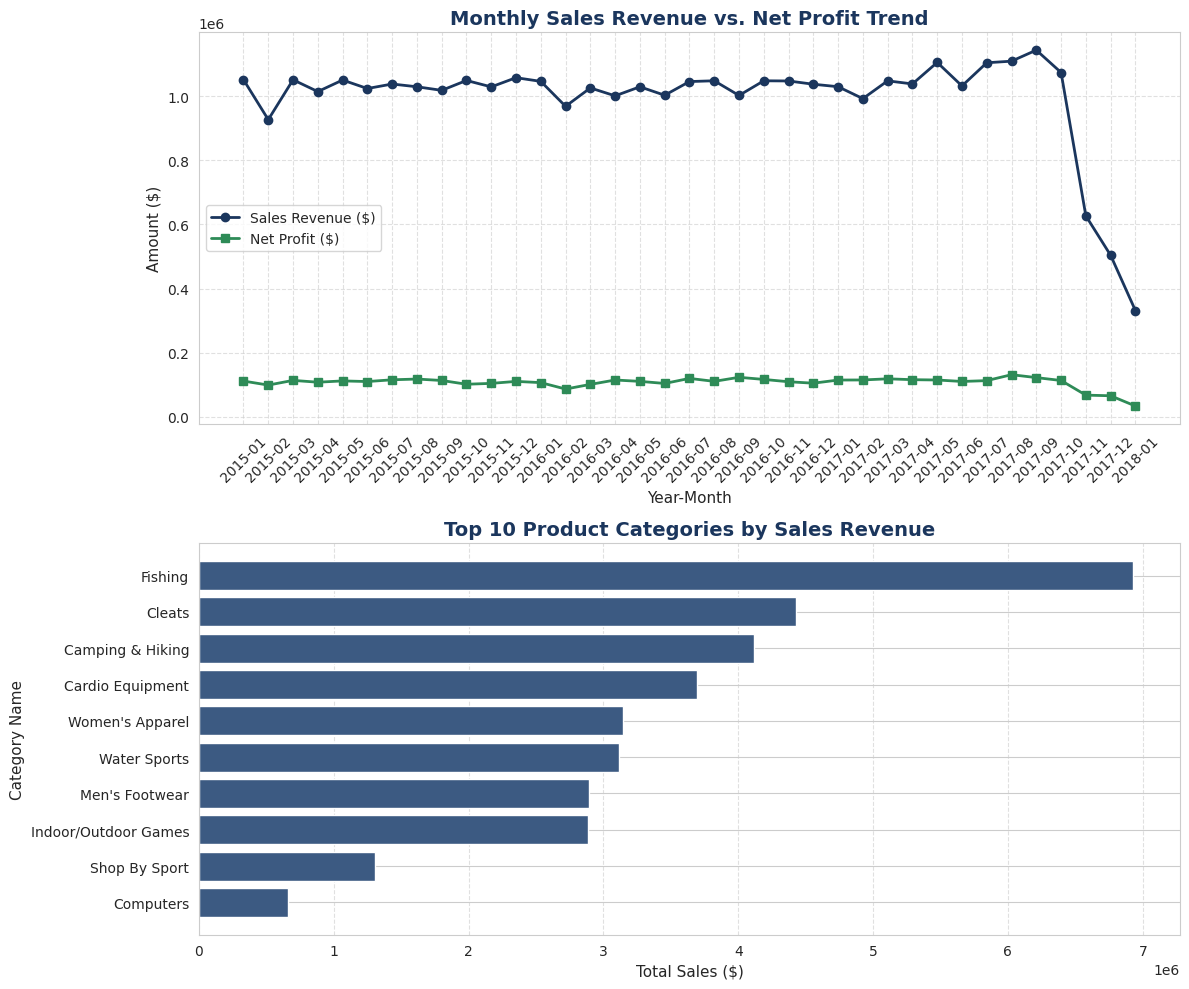


Visuals saved successfully to 'images/objective_1_sales_performance.png'.


In [14]:
# ==========================================
# OBJECTIVE 1: ANALYSE OVERALL SALES PERFORMANCE
# ==========================================

import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Ensure visualizations directory exists
import os
os.makedirs('images', exist_ok=True)

# 1. Calculate Key Sales Metrics
total_sales = df['Sales'].sum()
total_profit = df['Order Profit Per Order'].sum()
overall_profit_margin = (total_profit / total_sales) * 100
total_orders = df['Order Id'].nunique()

print("="*50)
print("OBJECTIVE 1: EXECUTIVE SUMMARY METRICS")
print("="*50)
print(f"Total Sales Revenue      : ${total_sales:,.2f}")
print(f"Total Net Profit         : ${total_profit:,.2f}")
print(f"Overall Profit Margin    : {overall_profit_margin:.2f}%")
print(f"Total Unique Orders      : {total_orders:,}")

# 2. Monthly Trend Aggregation
monthly_perf = df.groupby('YearMonth').agg(
    Monthly_Sales=('Sales', 'sum'),
    Monthly_Profit=('Order Profit Per Order', 'sum')
).reset_index()

# 3. Top Categories Aggregation
top_categories = df.groupby('Category Name').agg(
    Total_Sales=('Sales', 'sum')
).sort_values(by='Total_Sales', ascending=False).head(10).reset_index()

# ==========================================
# GENERATE RECOMMENDED VISUALIZATIONS
# ==========================================
fig, axes = plt.subplots(2, 1, figsize=(12, 10))

# Visual A: Line Chart - Monthly Sales Revenue vs Net Profit
axes[0].plot(monthly_perf['YearMonth'], monthly_perf['Monthly_Sales'], marker='o', color='#1B365D', linewidth=2, label='Sales Revenue ($)')
axes[0].plot(monthly_perf['YearMonth'], monthly_perf['Monthly_Profit'], marker='s', color='#2E8B57', linewidth=2, label='Net Profit ($)')
axes[0].set_title('Monthly Sales Revenue vs. Net Profit Trend', fontsize=14, fontweight='bold', color='#1B365D')
axes[0].set_xlabel('Year-Month', fontsize=11)
axes[0].set_ylabel('Amount ($)', fontsize=11)
axes[0].tick_params(axis='x', rotation=45)
axes[0].legend()
axes[0].grid(True, linestyle='--', alpha=0.6)

# Visual B: Bar Chart - Top 10 Product Categories by Sales
top_categories_sorted = top_categories.sort_values(by='Total_Sales', ascending=True)
axes[1].barh(top_categories_sorted['Category Name'], top_categories_sorted['Total_Sales'], color='#3C5A82')
axes[1].set_title('Top 10 Product Categories by Sales Revenue', fontsize=14, fontweight='bold', color='#1B365D')
axes[1].set_xlabel('Total Sales ($)', fontsize=11)
axes[1].set_ylabel('Category Name', fontsize=11)
axes[1].grid(axis='x', linestyle='--', alpha=0.6)

plt.tight_layout()
plt.savefig('images/objective_1_sales_performance.png', dpi=300)
plt.show()

print("\nVisuals saved successfully to 'images/objective_1_sales_performance.png'.")